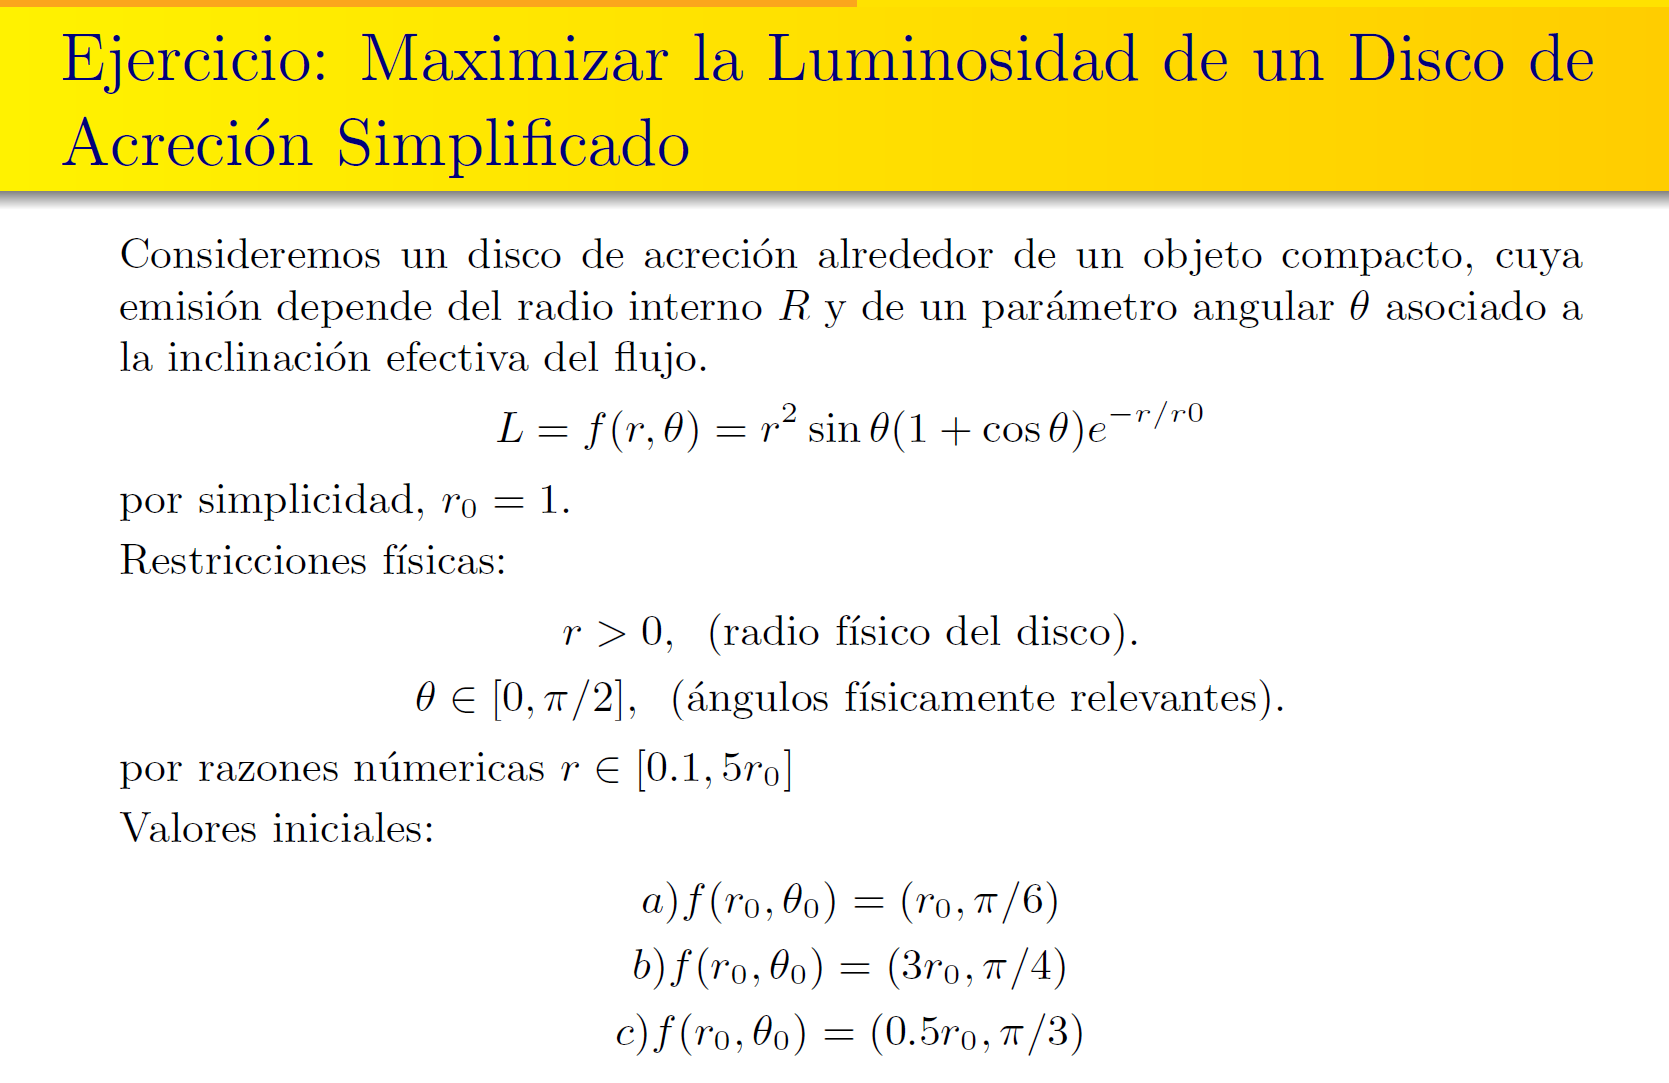

In [3]:
import numpy as np

r0 = 1
r_min = 0.1
r_max = 5
theta_min = 0
theta_max = np.pi / 2

tolerancia = 1e-6
max_iteraciones = 100
max_iteraciones_seccion_aurea = 100
tolerancia_seccion_aurea = 1e-8

print('r0 =', r0)
print('Intervalo del radio = [', r_min, ',', r_max, ']')
print('Intervalo del ángulo = [', theta_min, ',', theta_max, '] radianes')
print('Tolerancia del algoritmo =', tolerancia)

r0 = 1
Intervalo del radio = [ 0.1 , 5 ]
Intervalo del ángulo = [ 0 , 1.5707963267948966 ] radianes
Tolerancia del algoritmo = 1e-06


In [9]:
#Caso A
r = r0
theta = np.pi / 6

print('Punto inicial: r =', r, ', theta =', theta)
factor_radio = r ** 2
factor_angular = np.sin(theta) * (1 + np.cos(theta))
factor_exp = np.exp(-r / r0)
L_inicial = factor_radio * factor_angular * factor_exp
print('Luminosidad inicial =', L_inicial)

historial_a = []
convergio_a = False

for iteracion in range(1, max_iteraciones + 1):
    r_anterior = r
    theta_anterior = theta

    # maximizar respecto a r con theta fija
    a = r_min
    b = r_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)

    L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)
    L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)

    for paso_r in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)

    r = (a + b) / 2

    # maximizar respecto a theta con r fija
    a = theta_min
    b = theta_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)

    L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)
    L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)

    for paso_theta in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)

    theta = (a + b) / 2

    factor_radio = r ** 2
    factor_angular = np.sin(theta) * (1 + np.cos(theta))
    factor_exp = np.exp(-r / r0)
    L_actual = factor_radio * factor_angular * factor_exp
    cambio_r = abs(r - r_anterior)
    cambio_theta = abs(theta - theta_anterior)
    cambio_maximo = max(cambio_r, cambio_theta)
    historial_a.append([iteracion, r, theta, L_actual, cambio_r, cambio_theta])

   
    if cambio_maximo < tolerancia:
        convergio_a = True
        break

print('\nResultado caso a')
print('Convergió =', convergio_a)
print('Radio óptimo =', r)
print('Ángulo óptimo (rad) =', theta)
print('Ángulo óptimo (grados) =', np.degrees(theta))
print('Luminosidad máxima encontrada =', L_actual)

Punto inicial: r = 1 , theta = 0.5235987755982988
Luminosidad inicial = 0.3432361913779671

Resultado caso a
Convergió = True
Radio óptimo = 1.9999999764059475
Ángulo óptimo (rad) = 1.0471975500525001
Ángulo óptimo (grados) = 59.99999993444804
Luminosidad máxima encontrada = 0.7032227598676132


In [13]:
#Caso B
r = 3 * r0
theta = np.pi / 4
print('Punto inicial: r =', r, ', theta =', theta)
L_inicial = r ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r / r0)
print('Luminosidad inicial =', L_inicial)

historial_b = []
convergio_b = False

for iteracion in range(1, max_iteraciones + 1):
    r_anterior = r
    theta_anterior = theta
    a = r_min
    b = r_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)
    L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)
    L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)
    for paso_r in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)
    r = (a + b) / 2

    a = theta_min
    b = theta_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)
    L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)
    L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)
    for paso_theta in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)
    theta = (a + b) / 2

    L_actual = r ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r / r0)
    cambio_r = abs(r - r_anterior)
    cambio_theta = abs(theta - theta_anterior)
    cambio_maximo = max(cambio_r, cambio_theta)
    historial_b.append([iteracion, r, theta, L_actual, cambio_r, cambio_theta])
    if cambio_maximo < tolerancia:
        convergio_b = True
        break

print('\nResultado caso b')
print('Convergió =', convergio_b)
print('Radio óptimo =', r)
print('Ángulo óptimo (rad) =', theta)
print('Ángulo óptimo (grados) =', np.degrees(theta))
print('Luminosidad máxima encontrada =', L_actual)

Punto inicial: r = 3 , theta = 0.7853981633974483
Luminosidad inicial = 0.5408847705802214

Resultado caso b
Convergió = True
Radio óptimo = 1.9999999713508732
Ángulo óptimo (rad) = 1.047197554295047
Ángulo óptimo (grados) = 60.000000177528065
Luminosidad máxima encontrada = 0.7032227598676132


In [14]:
#Caso C
r = 0.5 * r0
theta = np.pi / 3
print('Punto inicial: r =', r, ', theta =', theta)
L_inicial = r ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r / r0)
print('Luminosidad inicial =', L_inicial)

historial_c = []
convergio_c = False

for iteracion in range(1, max_iteraciones + 1):
    r_anterior = r
    theta_anterior = theta
    a = r_min
    b = r_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)
    L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)
    L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)
    for paso_r in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = x2 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x2 / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = x1 ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-x1 / r0)
    r = (a + b) / 2

    a = theta_min
    b = theta_max
    proporcion = (np.sqrt(5) - 1) / 2
    x1 = b - proporcion * (b - a)
    x2 = a + proporcion * (b - a)
    L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)
    L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)
    for paso_theta in range(max_iteraciones_seccion_aurea):
        if abs(b - a) < tolerancia_seccion_aurea:
            break
        if L_x1 < L_x2:
            a = x1
            x1 = x2
            L_x1 = L_x2
            x2 = a + proporcion * (b - a)
            L_x2 = r ** 2 * np.sin(x2) * (1 + np.cos(x2)) * np.exp(-r / r0)
        else:
            b = x2
            x2 = x1
            L_x2 = L_x1
            x1 = b - proporcion * (b - a)
            L_x1 = r ** 2 * np.sin(x1) * (1 + np.cos(x1)) * np.exp(-r / r0)
    theta = (a + b) / 2

    L_actual = r ** 2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r / r0)
    cambio_r = abs(r - r_anterior)
    cambio_theta = abs(theta - theta_anterior)
    cambio_maximo = max(cambio_r, cambio_theta)
    historial_c.append([iteracion, r, theta, L_actual, cambio_r, cambio_theta])

    if cambio_maximo < tolerancia:
        convergio_c = True
        break

print('\nResultado caso c')
print('Convergió =', convergio_c)
print('Radio óptimo =', r)
print('Ángulo óptimo (rad) =', theta)
print('Ángulo óptimo (grados) =', np.degrees(theta))
print('Luminosidad máxima encontrada =', L_actual)

Punto inicial: r = 0.5 , theta = 1.0471975511965976
Luminosidad inicial = 0.19697660980697826

Resultado caso c
Convergió = True
Radio óptimo = 1.9999999764059475
Ángulo óptimo (rad) = 1.0471975500525001
Ángulo óptimo (grados) = 59.99999993444804
Luminosidad máxima encontrada = 0.7032227598676132
